# Linear model test — is the drone's `u -> az` relation linear?

**Integration week, Track B, steps 1-3.**

Goal of this notebook:

1. load and **validate** the recorded dataset,
2. check the **order** of the dynamics (is the step response first order?),
3. check whether the relation `u -> az` is **linear**,
4. **identify** the model by least squares and validate it on unseen experiments.

Recall the structure of the problem:

```
u  -->  [ unknown dynamics ]  -->  az  --(integrate)-->  vz  --(integrate)-->  z
        ^                                ^
   this is what we identify         known calculus, free
```

Only `u` and `az` were recorded, so the identification is **SISO**.

## 0. Setup

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Ts      = 0.05            # sampling period [s]  (justified in section 2)
N_ROWS  = 1500            # experiments to load; set to None to use all 3000
FILE_IN , FILE_OUT = '../data/bdd_in_mat_05.csv.gz', '../data/bdd_out_mat_05.csv.gz'

plt.rcParams['figure.figsize'] = (11, 3.2)
plt.rcParams['axes.grid']      = True
np.set_printoptions(suppress=True, precision=4)

## 1. Load the data

Each **row is one independent experiment**, each **column one time sample**.

In [21]:
U = pd.read_csv(FILE_IN , header=None, nrows=N_ROWS).to_numpy()
Y = pd.read_csv(FILE_OUT, header=None, nrows=N_ROWS).to_numpy()

n_exp, n_t = U.shape
t = np.arange(n_t) * Ts

print(f'{n_exp} experiments x {n_t} samples  ->  {n_t*Ts:.0f} s per experiment at Ts = {Ts} s')
print(f'u  in [{U.min():.3f}, {U.max():.3f}]      az in [{Y.min():.1f}, {Y.max():.1f}] m/s^2')
print(f'az at rest (first 40 samples, u = 0): mean {Y[:, :40].mean():.4f}  <- gravity')

1500 experiments x 2000 samples  ->  100 s per experiment at Ts = 0.05 s
u  in [-1.000, 1.000]      az in [-341.1, 412.9] m/s^2
az at rest (first 40 samples, u = 0): mean -9.8103  <- gravity


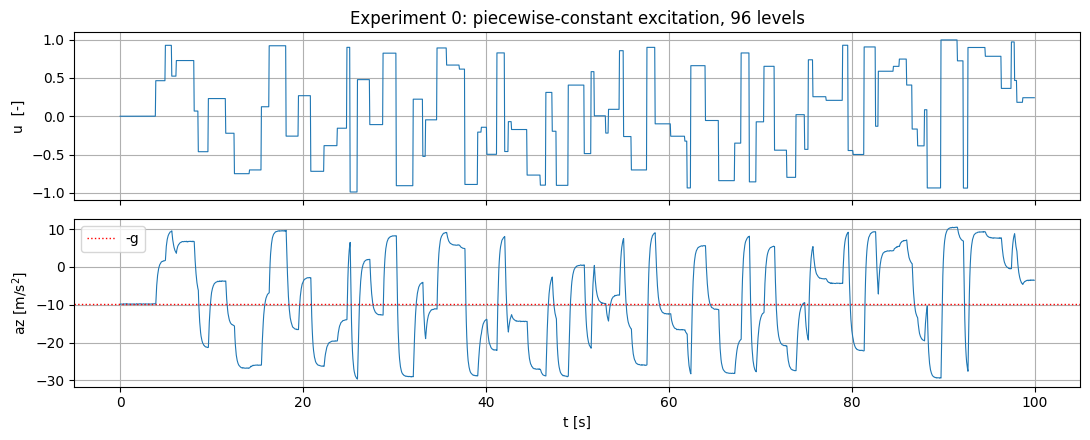

In [22]:
# what one experiment looks like
i = 0
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(11, 4.5))
ax[0].plot(t, U[i], lw=.8);  ax[0].set_ylabel('u  [-]')
ax[1].plot(t, Y[i], lw=.8);  ax[1].set_ylabel('az [m/s$^2$]'); ax[1].set_xlabel('t [s]')
ax[0].set_title(f'Experiment {i}: piecewise-constant excitation, {len(np.unique(U[i]))} levels')
ax[1].axhline(-9.81, color='r', ls=':', lw=1, label='-g'); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Validate the dataset

The brief warns the sensor was *"somewhat unreliable"*. Two independent checks, both physics-based:

* **rest check** — every experiment starts with 40 samples at `u = 0`, so `az` must read $-g \approx -9.81$;
* **amplitude check** — the drone physically cannot exceed a few $g$.

In [23]:
rest = Y[:, :40].mean(axis=1)      # should be about -9.81
peak = np.abs(Y).max(axis=1)       # should be about 30

bad = (np.abs(rest + 9.81) > 0.5) | (peak > 60)

print(f'rest az : median {np.median(rest):.3f}   min {rest.min():.3f}   max {rest.max():.3f}')
print(f'peak|az|: median {np.median(peak):.1f}     max {peak.max():.1f}')
print(f'\nCORRUPTED EXPERIMENTS: {bad.sum()} / {n_exp}  -> rows {np.flatnonzero(bad)}')

rest az : median -9.810   min -9.832   max -9.791
peak|az|: median 29.9     max 412.9

CORRUPTED EXPERIMENTS: 3 / 1500  -> rows [ 122  455 1233]


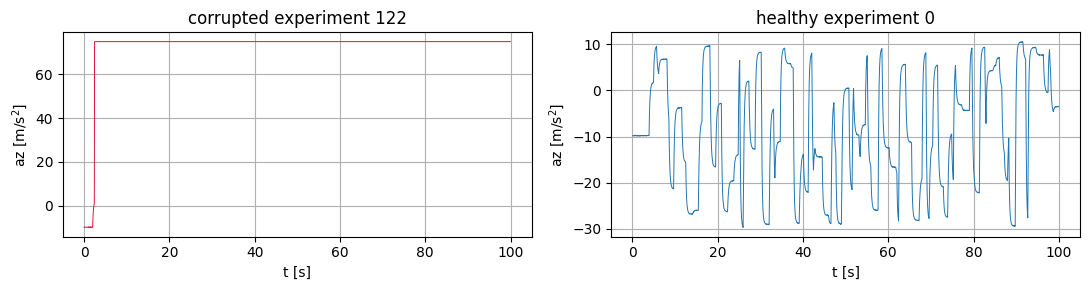

1497 experiments kept


In [24]:
if bad.any():
    b = np.flatnonzero(bad)[0]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    ax[0].plot(t, Y[b], lw=.7, color='crimson'); ax[0].set_title(f'corrupted experiment {b}')
    ax[1].plot(t, Y[0], lw=.7);                  ax[1].set_title('healthy experiment 0')
    for a in ax: a.set_xlabel('t [s]'); a.set_ylabel('az [m/s$^2$]')
    plt.tight_layout(); plt.show()

U, Y = U[~bad], Y[~bad]
n_exp = len(U)
print(f'{n_exp} experiments kept')

### Helper: locate the constant-`u` holds

The excitation is a staircase: `u` is held for about 1 s before jumping. Inside a hold that is long
enough, `az` reaches **steady state** — that is what lets us read the static characteristic.

In [25]:
def holds(u, min_len=1):
    # Return the [start, stop) index pairs over which u is constant.
    edges = np.concatenate(([0], np.flatnonzero(np.diff(u)) + 1, [len(u)]))
    return [(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a >= min_len]

L = [b - a for a, b in holds(U[0])]
print(f'experiment 0: {len(L)} holds, length min {min(L)}  median {int(np.median(L))}  max {max(L)} samples')
print(f'             = {np.median(L)*Ts:.2f} s per hold on average')

experiment 0: 96 holds, length min 5  median 21  max 40 samples
             = 1.05 s per hold on average


In [26]:
# measurement noise: scatter of az inside holds that have fully settled.
# Successive differences remove any residual drift, so this measures the sensor alone.
res = []
for i in range(min(200, n_exp)):
    for a, b in holds(U[i], 30):
        seg = Y[i, a+20:b]                         # skip 20 samples = 4 tau of transient
        if len(seg) > 5: res.append(np.diff(seg) / np.sqrt(2))
res = np.concatenate(res)
noise_std = res.std()

print(f'measurement noise inside settled holds: std = {noise_std:.4f} m/s^2')
print(f'largest single deviation              : {np.abs(res).max():.3f} m/s^2')
print('-> no isolated spikes survive inside the holds: the corruption is whole-experiment,')
print('   not sample-wise, so cleaning means DROPPING EXPERIMENTS, not filtering samples')

measurement noise inside settled holds: std = 0.0451 m/s^2
largest single deviation              : 0.220 m/s^2
-> no isolated spikes survive inside the holds: the corruption is whole-experiment,
   not sample-wise, so cleaning means DROPPING EXPERIMENTS, not filtering samples


## 3. Order of the dynamics

Criterion from the course:

| step response | conclusion |
|---|---|
| no overshoot, **nonzero** tangent at the origin | **first order** |
| overshoot possible, **zero** tangent at the origin | second order or higher |

We overlay the response to several individual steps, normalised from 0 to 1.

In [27]:
def step_responses(n_exp_use=60, min_jump=0.4, min_len=30):
    # Collect normalised responses to isolated input steps.
    out = []
    for i in range(min(n_exp_use, n_exp)):
        hs = holds(U[i], 1)
        for (a0, b0), (a1, b1) in zip(hs[:-1], hs[1:]):
            if (b1 - a1) >= min_len and abs(U[i, a1] - U[i, a0]) > min_jump and (b0 - a0) >= 15:
                # t = 0 is the sample at which u jumps. az[k] reacts to u[k-1], so the
                # response only starts at the NEXT sample: one sample of input delay.
                y0, y1 = Y[i, a1], Y[i, b1-5:b1].mean()
                if abs(y1 - y0) > 5:
                    out.append((Y[i, a1:a1+min_len] - y0) / (y1 - y0))
    return np.array(out)

R    = step_responses()
mean = R.mean(axis=0)
tt   = np.arange(len(mean)) * Ts

# 63.2 % crossing, interpolated between samples (Ts = 0.05 s is too coarse to read directly)
k   = np.argmax(mean > 0.632)
tau = np.interp(0.632, mean[:k+1], tt[:k+1])

print(f'{len(R)} isolated steps collected')
print(f'time constant from the 63.2% crossing: tau = {tau:.3f} s')

701 isolated steps collected
time constant from the 63.2% crossing: tau = 0.196 s


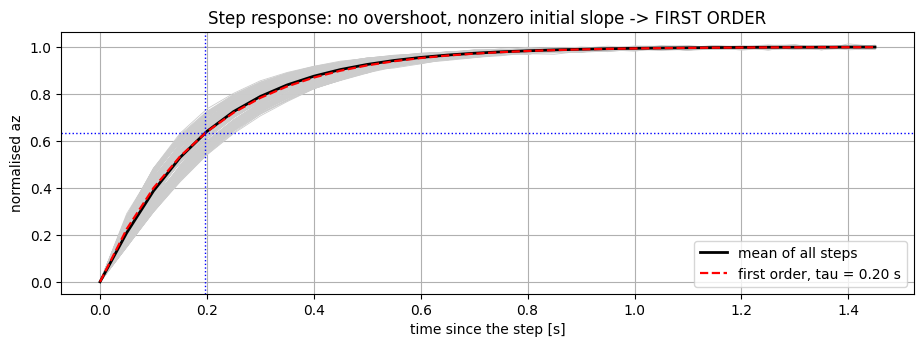

In [28]:
tt = np.arange(R.shape[1]) * Ts
plt.figure(figsize=(11, 3.4))
plt.plot(tt, R[:150].T, color='0.8', lw=.6)
plt.plot(tt, R.mean(axis=0), 'k', lw=2, label='mean of all steps')
plt.plot(tt, 1 - np.exp(-tt / tau), 'r--', lw=1.6, label=f'first order, tau = {tau:.2f} s')
plt.axhline(0.632, color='b', ls=':', lw=1); plt.axvline(tau, color='b', ls=':', lw=1)
plt.xlabel('time since the step [s]'); plt.ylabel('normalised az'); plt.legend()
plt.title('Step response: no overshoot, nonzero initial slope -> FIRST ORDER'); plt.show()

### This justifies `Ts = 0.05 s`

For a first-order system the 10-90 % rise time is $t_r = \tau\ln 9 \approx 2.2\,\tau$, and the course
rule of thumb is $T_e \approx t_r/10$, i.e. $T_e \approx 0.22\,\tau$.

In [29]:
t_r = tau * np.log(9)
print(f'tau       = {tau:.3f} s')
print(f'rise time = 2.2 tau = {t_r:.3f} s')
print(f'Te ~ t_r/10         = {t_r/10:.3f} s   ->  Ts = 0.05 s is the right order of magnitude')
print(f'Ts / tau            = {Ts/tau:.2f}     ->  about {tau/Ts:.0f} samples per time constant')

tau       = 0.196 s
rise time = 2.2 tau = 0.431 s
Te ~ t_r/10         = 0.043 s   ->  Ts = 0.05 s is the right order of magnitude
Ts / tau            = 0.26     ->  about 4 samples per time constant


## 4. Is it linear?

A first-order **linear** system would satisfy

$$a_{z,ss}(u) = K\,u + c$$

with a **constant** gain $K$ at every amplitude. We read the steady-state value at the end of every
long hold and plot it against `u`.

In [30]:
u_ss, az_ss = [], []
for i in range(n_exp):
    for a, b in holds(U[i], 30):                       # >= 1.5 s  = 7 tau : fully settled
        u_ss.append(U[i, a]); az_ss.append(np.median(Y[i, b-8:b]))
u_ss, az_ss = np.array(u_ss), np.array(az_ss)
print(f'{len(u_ss)} settled (u, az) pairs')

39264 settled (u, az) pairs


In [31]:
p1 = np.polyfit(u_ss, az_ss, 1)
p3 = np.polyfit(u_ss, az_ss, 3)
r1 = az_ss - np.polyval(p1, u_ss)
r3 = az_ss - np.polyval(p3, u_ss)

print(f'linear fit   az_ss = {p1[0]:.3f} u {p1[1]:+.3f}      residual rms = {r1.std():.4f} m/s^2')
print(f'cubic fit                                  residual rms = {r3.std():.4f} m/s^2')
print(f'measurement noise (section 2)              std          = {noise_std:.4f} m/s^2')
print(f'\n-> the linear residual is {r1.std()/noise_std:.0f}x the measurement noise.')
print('   The gap is NOT noise, it is structure: the static characteristic is curved.')

linear fit   az_ss = 22.465 u -9.811      residual rms = 0.9004 m/s^2
cubic fit                                  residual rms = 0.0792 m/s^2
measurement noise (section 2)              std          = 0.0451 m/s^2

-> the linear residual is 20x the measurement noise.
   The gap is NOT noise, it is structure: the static characteristic is curved.


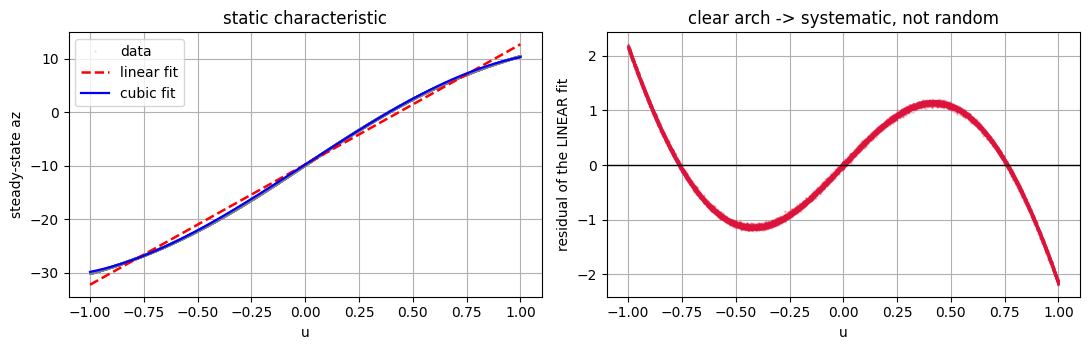

In [32]:
ug = np.linspace(-1, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].plot(u_ss, az_ss, '.', ms=1, alpha=.25, color='0.5', label='data')
ax[0].plot(ug, np.polyval(p1, ug), 'r--', lw=1.8, label='linear fit')
ax[0].plot(ug, np.polyval(p3, ug), 'b-',  lw=1.6, label='cubic fit')
ax[0].set_xlabel('u'); ax[0].set_ylabel('steady-state az'); ax[0].legend()
ax[0].set_title('static characteristic')

ax[1].plot(u_ss, r1, '.', ms=1, alpha=.3, color='crimson')
ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('u'); ax[1].set_ylabel('residual of the LINEAR fit')
ax[1].set_title('clear arch -> systematic, not random')
plt.tight_layout(); plt.show()

In [33]:
# local (incremental) gain: constant <=> linear
print(' u range        n     mean az_ss    local gain dAz/du')
for lo in np.arange(-1, 1, 0.2):
    m = (u_ss >= lo) & (u_ss < lo + 0.2)
    if m.sum() > 30:
        k = np.polyfit(u_ss[m], az_ss[m], 1)[0]
        print(f'  {lo:+.1f}..{lo+0.2:+.1f}  {m.sum():6d}   {az_ss[m].mean():9.2f}      {k:7.2f}')

 u range        n     mean az_ss    local gain dAz/du
  -1.0..-0.8    3851      -28.88        13.01
  -0.8..-0.6    3862      -25.89        16.93
  -0.6..-0.4    3741      -22.07        20.96
  -0.4..-0.2    3763      -17.56        24.34
  -0.2..-0.0    3697      -12.47        26.33
  -0.0..+0.2    5277       -7.95        26.41
  +0.2..+0.4    3764       -2.06        24.35
  +0.4..+0.6    3709        2.48        20.95
  +0.6..+0.8    3766        6.26        16.95
  +0.8..+1.0    3834        9.25        13.00


### Verdict

**The system is NOT linear.** The dynamics are first order, but the *input* enters through a
saturating, odd-symmetric characteristic: the incremental gain is about **27** near `u = 0` and drops
to about **13** at `|u| = 0.9` — a factor of two.

This is a **Hammerstein** structure: a static nonlinearity followed by linear dynamics.

```
u --> [ f(.) static, saturating ] --> [ 1/(1+tau s) ] --> + (-g) --> az
```

Good news: if we write $f$ as a polynomial, the model is **still linear in the parameters**, so plain
least squares still applies.

## 5. Identification by least squares

Discrete first-order model, one step ahead:

$$a_z[k] \;=\; a\,a_z[k-1] \;+\; \sum_j b_j\,g_j\big(u[k-1]\big) \;+\; c$$

The functions $g_j$ are **fixed and chosen by us**. Whatever we pick, the model stays **linear in the
parameters** $\theta = (a, b_1 \dots b_m, c)$, so ordinary least squares still applies:

$$\hat\theta = (X^\top X)^{-1}X^\top y$$

Note the `[k-1]`: section 3 showed **one sample of input delay**, so `u[k-1]` drives `az[k]`.

In [34]:
split  = int(0.75 * n_exp)
train, test = np.arange(split), np.arange(split, n_exp)
print(f'{len(train)} experiments for identification, {len(test)} held out for validation')

def design(rows, basis):
    # Stack the regressors phi_k = [az[k-1], g_1(u[k-1]) ... g_m(u[k-1]), 1] and targets az[k].
    X, y = [], []
    for i in rows:
        u, az0, az1 = U[i, :-1], Y[i, :-1], Y[i, 1:]
        X.append(np.column_stack([az0] + [g(u) for g in basis] + [np.ones_like(u)]))
        y.append(az1)
    return np.vstack(X), np.concatenate(y)

def identify(basis, rows=None):
    X, y = design(train if rows is None else rows, basis)
    theta, *_ = np.linalg.lstsq(X, y, rcond=None)     # safer than inv(X.T @ X)
    return theta

def static_map(th, basis, u):
    # Steady state of az for a constant u:  f(u) = (sum b_j g_j(u) + c) / (1 - a)
    a, b, c = th[0], th[1:-1], th[-1]
    return (sum(bj * g(u) for bj, g in zip(b, basis)) + c) / (1 - a)

1122 experiments for identification, 375 held out for validation


### Which shape for the nonlinearity: powers, or `tanh`?

Section 4 showed the static characteristic **saturates**. Two candidate shapes:

* **odd polynomial** $b_1u + b_3u^3 + b_5u^5$ — flexible, but it *diverges* outside the fitted range;
* **`tanh`** — saturates by construction, which is what the data actually does, and needs one term.

**Why no separate "sigmoid" option?** Because it is the same model:

$$\sigma(\beta u)=\frac{1}{1+e^{-\beta u}}=\tfrac12\Big(1+\tanh\tfrac{\beta u}{2}\Big)$$

so $b\,\sigma(\beta u)+c$ and $\tfrac{b}{2}\tanh\!\big(\tfrac{\beta u}{2}\big)+\big(c+\tfrac{b}{2}\big)$
are identical — the constant is absorbed by $c$. Fitting a sigmoid gives exactly the same residual as
fitting a `tanh` with half the slope. The cell below checks this numerically.

**One catch:** $\beta$ sits *inside* the nonlinearity, so the model is **not** linear in $\beta$. We
use *separable least squares*: scan $\beta$ on a grid and solve the linear problem for
$(a,b,c)$ at each one. The scan uses the **training** experiments only — the test set stays untouched
for the final comparison.

In [35]:
betas = np.arange(0.4, 2.01, 0.05)
err_b = []
for bt in betas:
    basis = [lambda u, bt=bt: np.tanh(bt * u)]       # bt=bt freezes the value in the closure
    X, y  = design(train, basis)
    err_b.append((y - X @ identify(basis)).std())
err_b    = np.array(err_b)
beta_opt = betas[err_b.argmin()]

print(f'best beta = {beta_opt:.2f}   (training residual {err_b.min():.4f} m/s^2)')

# sigmoid equivalence, numerically
b_tanh = [lambda u: np.tanh(beta_opt * u)]
b_sigm = [lambda u: 1.0 / (1.0 + np.exp(-2 * beta_opt * u))]
X1, y1 = design(train, b_tanh); X2, y2 = design(train, b_sigm)
print(f'tanh(beta u)      residual = {(y1 - X1 @ identify(b_tanh)).std():.6f}')
print(f'sigmoid(2 beta u) residual = {(y2 - X2 @ identify(b_sigm)).std():.6f}   <- identical, same model')

best beta = 0.90   (training residual 0.2075 m/s^2)
tanh(beta u)      residual = 0.207510
sigmoid(2 beta u) residual = 0.207510   <- identical, same model


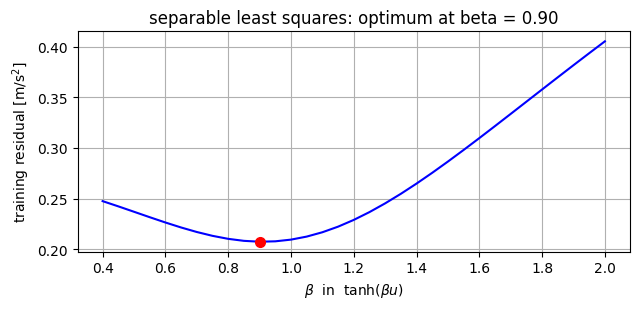

In [36]:
plt.figure(figsize=(6.5, 3.2))
plt.plot(betas, err_b, 'b-'); plt.plot(beta_opt, err_b.min(), 'ro', ms=7)
plt.xlabel(r'$\beta$  in  $\tanh(\beta u)$'); plt.ylabel('training residual [m/s$^2$]')
plt.title(f'separable least squares: optimum at beta = {beta_opt:.2f}')
plt.tight_layout(); plt.show()

### Fit the candidate models

In [37]:
BASES = {
    'A  linear      ': [lambda u: u],
    'B  poly u,u3,u5': [lambda u: u, lambda u: u**3, lambda u: u**5],
    'C  tanh(u)     ': [lambda u: np.tanh(beta_opt * u)],
    'D  tanh(u) + u ': [lambda u: np.tanh(beta_opt * u), lambda u: u],
}
theta = {name: identify(b) for name, b in BASES.items()}

for name, b in BASES.items():
    th = theta[name]; a = th[0]
    print(f'{name}  theta = {np.round(th, 4)}')
    print(f'{"":17s} tau = {-Ts/np.log(a):.4f} s   (step response gave {tau:.3f} s)'
          f'   offset = {th[-1]/(1-a):+.3f} m/s^2   (gravity -9.81)')

A  linear        theta = [ 0.7836  4.966  -2.1219]
                  tau = 0.2051 s   (step response gave 0.196 s)   offset = -9.807 m/s^2   (gravity -9.81)
B  poly u,u3,u5  theta = [ 0.7804  5.8046 -1.5412  0.3459 -2.1545]
                  tau = 0.2016 s   (step response gave 0.196 s)   offset = -9.809 m/s^2   (gravity -9.81)
C  tanh(u)       theta = [ 0.7804  6.4373 -2.1545]
                  tau = 0.2016 s   (step response gave 0.196 s)   offset = -9.809 m/s^2   (gravity -9.81)
D  tanh(u) + u   theta = [ 0.7804  6.5564 -0.0934 -2.1545]
                  tau = 0.2016 s   (step response gave 0.196 s)   offset = -9.809 m/s^2   (gravity -9.81)


Two **free physical checks** on every row above: the identified pole reproduces the time constant
measured independently from the step responses, and the constant term reproduces **gravity**. If
either were off, the structure would be wrong.

## 6. Validation on experiments never used for fitting

In [38]:
def simulate(th, basis, i):
    # Free run: only u is given, az is fed back from the model's own output.
    a, b, c = th[0], th[1:-1], th[-1]
    u  = U[i]
    az = np.empty(len(u)); az[0] = Y[i, 0]
    for k in range(len(u) - 1):
        az[k+1] = a*az[k] + sum(bj * g(u[k]) for bj, g in zip(b, basis)) + c
    return az

print(f'{"model":17s} {"params":>7s} {"one-step RMSE":>14s} {"free-run RMSE":>14s}')
score = {}
for name, basis in BASES.items():
    X, y = design(test, basis)
    one  = (y - X @ theta[name]).std()
    free = np.mean([np.sqrt(np.mean((simulate(theta[name], basis, i) - Y[i])**2))
                    for i in test[:100]])
    score[name] = (one, free)
    print(f'{name:17s} {len(theta[name]):7d} {one:14.4f} {free:14.4f}')

model              params  one-step RMSE  free-run RMSE
A  linear               3         0.2689         0.8370
B  poly u,u3,u5         5         0.2062         0.4438
C  tanh(u)              3         0.2062         0.4434
D  tanh(u) + u          4         0.2062         0.4438


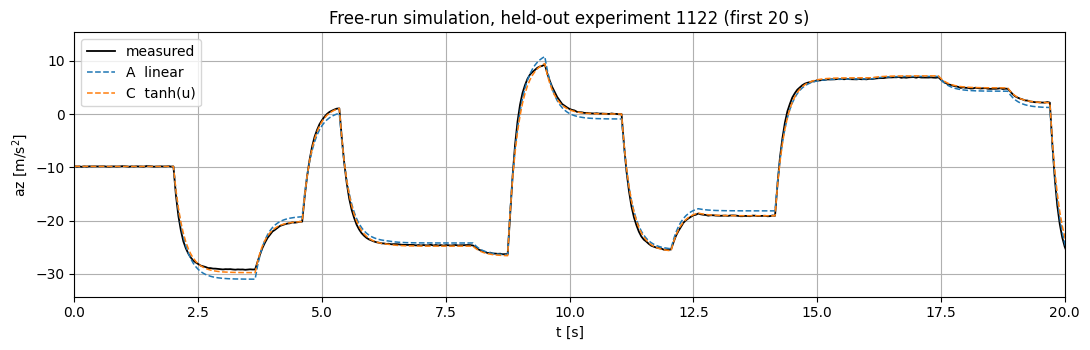

In [39]:
i = test[0]
plt.figure(figsize=(11, 3.6))
plt.plot(t, Y[i], 'k', lw=1.3, label='measured')
for name in ['A  linear      ', 'C  tanh(u)     ']:
    plt.plot(t, simulate(theta[name], BASES[name], i), lw=1.1, ls='--', label=name.strip())
plt.xlim(0, 20); plt.xlabel('t [s]'); plt.ylabel('az [m/s$^2$]')
plt.title(f'Free-run simulation, held-out experiment {i} (first 20 s)')
plt.legend(); plt.tight_layout(); plt.show()

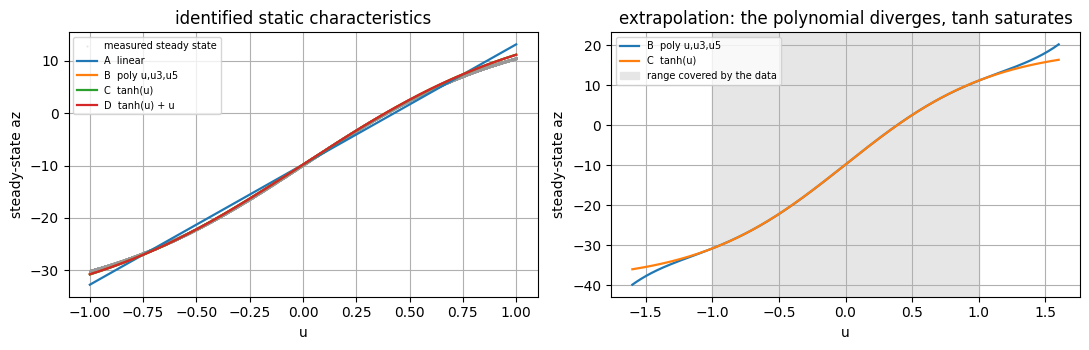

In [40]:
ug = np.linspace(-1, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

ax[0].plot(u_ss, az_ss, '.', ms=1, alpha=.25, color='0.6', label='measured steady state')
for name in BASES:
    ax[0].plot(ug, static_map(theta[name], BASES[name], ug), lw=1.6, label=name.strip())
ax[0].set_xlabel('u'); ax[0].set_ylabel('steady-state az'); ax[0].legend(fontsize=7)
ax[0].set_title('identified static characteristics')

ue = np.linspace(-1.6, 1.6, 400)                     # beyond the data range
for name in ['B  poly u,u3,u5', 'C  tanh(u)     ']:
    ax[1].plot(ue, static_map(theta[name], BASES[name], ue), lw=1.6, label=name.strip())
ax[1].axvspan(-1, 1, color='0.9', label='range covered by the data')
ax[1].set_xlabel('u'); ax[1].set_ylabel('steady-state az'); ax[1].legend(fontsize=7)
ax[1].set_title('extrapolation: the polynomial diverges, tanh saturates')
plt.tight_layout(); plt.show()

## 7. Conclusions

1. **Dataset** — a handful of experiments are completely corrupted and must be dropped (they are
   caught by the rest check and the amplitude check). Inside the surviving experiments there are no
   isolated spikes; the measurement noise is about **0.03-0.05 m/s²**.

2. **Order** — the step response has no overshoot and a nonzero initial slope: the dynamics are
   **first order**, with $\tau \approx 0.2$ s. This justifies $T_s = 0.05$ s
   ($T_e \approx t_r/10 \approx 0.22\,\tau$), roughly 4 samples per time constant.
   Two independent estimates agree: the 63 % crossing of the step response, and the pole $a$ of the
   identified model, $\tau = -T_s/\ln a$.

3. **One sample of input delay** — `az[k]` reacts to `u[k-1]`, not `u[k]`. The step response is
   visibly flat for exactly one sample after `u` jumps. This is not a detail: it is why the drone's
   controller is given `az_prev` and `u_prev` rather than the current values, and your Python
   environment **must reproduce the same delay** or the trained policy will not transfer.

4. **Linearity** — **not linear.** The steady-state gain falls from about 27 near `u = 0` to about 13
   at `|u| = 0.9`. The residual of the linear fit is an order of magnitude above the measurement
   noise and has a clear systematic shape, so it cannot be blamed on the sensor.

5. **Model** — a **Hammerstein** structure (static nonlinearity, then first-order dynamics) stays
   linear in its parameters for any fixed basis, so plain least squares fits it. It roughly
   **halves** the free-run error against the linear model, and recovers both the time constant and
   gravity on its own — strong evidence the structure is right.

6. **`tanh` beats the polynomial** — with $\beta \approx 0.9$, the single term
   $b\tanh(\beta u)$ matches the three-term odd polynomial $b_1u+b_3u^3+b_5u^5$ on both one-step and
   free-run error, using **two fewer parameters** — the same count as the linear model. Adding a
   linear term on top (model D) gives it a coefficient of about $-0.09$, i.e. nothing: `tanh` alone
   already has the right shape. It is also the physically honest choice, because it **saturates**
   outside the fitted range instead of diverging like a quintic.

   A **sigmoid** is not a separate option: $\sigma(\beta u)=\tfrac12(1+\tanh\tfrac{\beta u}{2})$, and
   the constant is absorbed by $c$, so it is the *same model* — the notebook verifies the two give
   identical residuals to six decimals.

### What this means for the rest of the project

* The brief expects a **neural-network** model; this notebook gives the **baseline to beat**, and the
  reason a nonlinear model is needed in the first place.
* Keep the same structure for the NN: predict `az` from (`az[k-1]`, `u[k-1]`), then integrate twice
  to get `vz` and `z`. Do not ask the network to learn the integrators.
* For Track B, this model (or the NN) is the plant inside your Gymnasium environment. The saturating
  gain matters: near hover the drone is **twice as responsive** as at full command, so a controller
  tuned only around hover will behave differently when it saturates.
* The `tanh` model is three numbers plus $\beta$. That makes it trivial to re-implement inside the
  Gym environment, and it is a good sanity check on whatever the neural network learns: if the NN
  disagrees with it inside $u\in[-1,1]$, suspect the NN.